In [ ]:
import os
import zipfile
import tensorflow as tf
import urllib.request

dataset_dir = "/content/cats_and_dogs_filtered"

urls = [
    "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip",
    "https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip",
]

if not (
    os.path.isdir(os.path.join(dataset_dir, "train", "cats"))
    and os.path.isdir(os.path.join(dataset_dir, "validation", "dogs"))
):
    zip_path = "/content/cats_and_dogs_filtered.zip"
    downloaded = False

    for url in urls:
        try:
            print("Trying:", url)
            request = urllib.request.Request(
                url, headers={"User-Agent": "Mozilla/5.0"}
            )
            with urllib.request.urlopen(request, timeout=60) as response:
                with open(zip_path, "wb") as f:
                    f.write(response.read())

            if not zipfile.is_zipfile(zip_path):
                raise ValueError("Downloaded file is not a valid ZIP")

            downloaded = True
            break
        except Exception as e:
            print("Download failed:", e)

    if not downloaded:
        raise RuntimeError(
            "Both downloads failed. Check Colab internet access."
        )

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("/content")

print("Dataset ready!")
print("Training directory:", os.path.join(dataset_dir, "train"))
print("Validation directory:", os.path.join(dataset_dir, "validation"))

Trying: https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip
Extracting dataset...
Dataset ready!
Training directory: /content/cats_and_dogs_filtered/train
Validation directory: /content/cats_and_dogs_filtered/validation


In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir + "/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

num_classes = len(train_ds.class_names)
print("Classes:", train_ds.class_names)

train_ds = train_ds.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.map(
    lambda x, y: (preprocess_input(x), y)
).prefetch(tf.data.AUTOTUNE)

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(num_classes, activation="softmax")(x)

model = Model(base_model.input, output)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history1 = model.fit(train_ds, validation_data=val_ds, epochs=5)

base_model.trainable = True

for layer in base_model.layers:
    layer.trainable = layer.name.startswith("block5")

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model.fit(train_ds, validation_data=val_ds, epochs=5)

loss, accuracy = model.evaluate(val_ds)
print(f"Validation accuracy: {accuracy:.4f}")
print(f"Validation loss: {loss:.4f}")

model.save("/content/vgg16_finetuned.keras")
print("Model saved successfully!")

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 28s 324ms/step - accuracy: 0.9345 - loss: 0.5071 - val_accuracy: 0.9810 - val_loss: 0.0714
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 217ms/step - accuracy: 0.9745 - loss: 0.1372 - val_accuracy: 0.9770 - val_loss: 0.1233
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 218ms/step - accuracy: 0.9820 - loss: 0.0937 - val_accuracy: 0.9810 - val_loss: 0.0722
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 221ms/step - accuracy: 0.9785 - loss: 0.0965 - val_accuracy: 0.9830 - val_loss: 0.0878
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 220ms/step - accuracy: 0.9850 - loss: 0.0743 - val_accuracy: 0.9830 - val_loss: 0.0788
Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 27s 335ms/step - accuracy: 0.9905 - loss: 0.0389 - val_accuracy: 0.9790 - val_loss: 0.0804
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 268ms/step - accuracy: 0.9945 - 

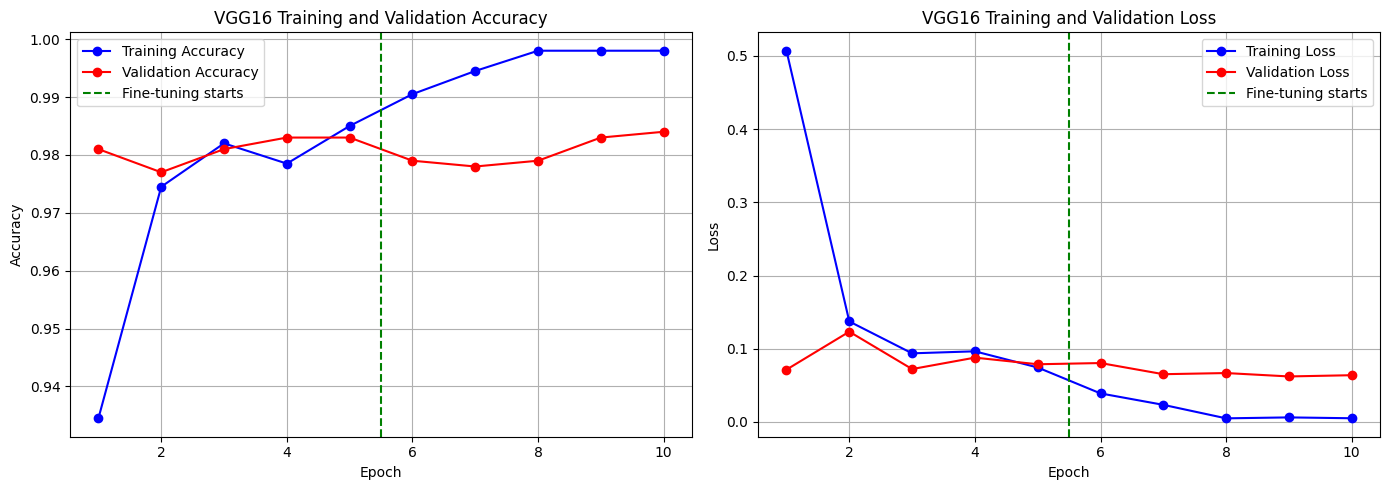

In [ ]:
import matplotlib.pyplot as plt

acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = (
    history1.history["val_accuracy"]
    + history2.history["val_accuracy"]
)

loss = history1.history["loss"] + history2.history["loss"]
val_loss = (
    history1.history["val_loss"]
    + history2.history["val_loss"]
)

epochs = range(1, len(acc) + 1)
fine_tune_start = len(history1.history["accuracy"]) + 0.5

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, "b-o", label="Training Accuracy")
plt.plot(epochs, val_acc, "r-o", label="Validation Accuracy")
plt.axvline(
    fine_tune_start,
    color="green",
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("VGG16 Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, "b-o", label="Training Loss")
plt.plot(epochs, val_loss, "r-o", label="Validation Loss")
plt.axvline(
    fine_tune_start,
    color="green",
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("VGG16 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.utils import load_img, img_to_array

model = tf.keras.models.load_model(
    "/content/vgg16_finetuned.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


Saving cat.jpeg to cat.jpeg


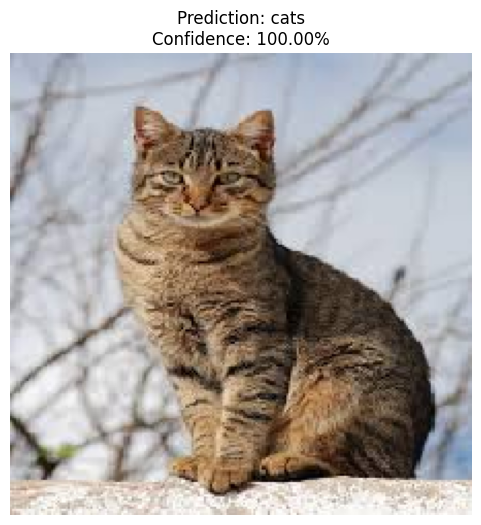

Predicted class: cats
Confidence: 100.00%


In [ ]:
uploaded = files.upload()

image_path = next(iter(uploaded))

img = load_img(image_path, target_size=(224, 224))
img_array = img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

predictions = model.predict(img_array, verbose=0)

class_names = ["cats", "dogs"]
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")